# Health Expenditure

In [2]:
from IPython.display import HTML,display

In [3]:
html_code = '''<h1 style="color:Blue;
background-color:lightyellow;
text-align:center;
font-size:40px;
font-family-Arial;
padding:15px;
border-bottom:4px solid orange;
border-radius :10px;">EDA Health Expenditure</h1>'''
display(HTML(html_code))

In [4]:
# Analyze Healthcare expenditure ,Heathcare spending per person and life expectancy across different countries over time

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = sns.load_dataset("healthexp")
df

,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9
...,...,...,...,...
269,2020,Germany,6938.983,81.1
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7


In [7]:
df.head()

,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [8]:
df.tail()

,Year,Country,Spending_USD,Life_Expectancy
269,2020,Germany,6938.983,81.1
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7
273,2020,USA,11859.179,77.0


In [9]:
df.shape

(274, 4)

In [10]:
df.columns

Index(['Year', 'Country', 'Spending_USD', 'Life_Expectancy'], dtype='object')

In [11]:
df.dtypes

Year                 int64
Country             object
Spending_USD       float64
Life_Expectancy    float64
dtype: object

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             274 non-null    int64  
 1   Country          274 non-null    object 
 2   Spending_USD     274 non-null    float64
 3   Life_Expectancy  274 non-null    float64
dtypes: float64(2), int64(1), object(1)
memory usage: 8.7+ KB


In [13]:
df.describe()

,Year,Spending_USD,Life_Expectancy
count,274.000000,274.000000,274.000000
mean,1996.992701,2789.338905,77.909489
std,14.180933,2194.939785,3.276263
min,1970.000000,123.993000,70.600000
25%,1985.250000,1038.357000,75.525000
50%,1998.000000,2295.578000,78.100000
75%,2009.000000,4055.610000,80.575000
max,2020.000000,11859.179000,84.700000


In [14]:
df["Country"].value_counts()
# number records available for each country

Country
Japan            51
USA              51
Germany          50
Canada           44
Great Britain    43
France           35
Name: count, dtype: int64

In [15]:
df["Country"].unique()

array(['Germany', 'France', 'Great Britain', 'Japan', 'USA', 'Canada'],
      dtype=object)

In [16]:
df["Country"].nunique()

6

In [17]:
# Check missing values
df.isnull().sum()

Year               0
Country            0
Spending_USD       0
Life_Expectancy    0
dtype: int64

In [18]:
missing = (df.isnull().sum()/len(df))*100
missing

Year               0.0
Country            0.0
Spending_USD       0.0
Life_Expectancy    0.0
dtype: float64

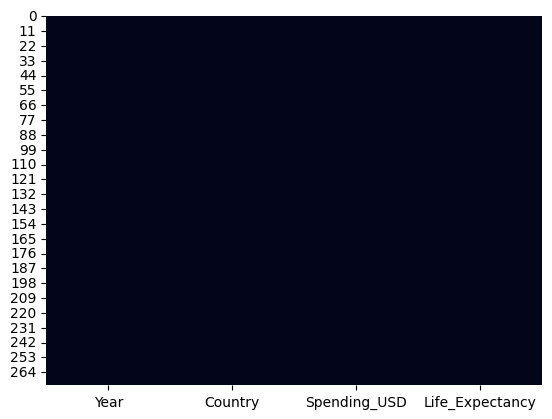

In [19]:
sns.heatmap(df.isnull(),cbar =False)
plt.show()

In [20]:
df.duplicated().sum()

0

In [21]:
df = df.drop_duplicates()
df

,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9
...,...,...,...,...
269,2020,Germany,6938.983,81.1
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7


In [22]:
# check min max value
print(df["Year"].min())

1970


In [23]:
print(df["Year"].max())

2020


In [24]:
print(df["Spending_USD"].min())

123.993


In [25]:
print(df["Life_Expectancy"].min())

70.6


In [26]:
df["Decade"] = (df["Year"]//10)*10
df

,Year,Country,Spending_USD,Life_Expectancy,Decade
0,1970,Germany,252.311,70.6,1970
1,1970,France,192.143,72.2,1970
2,1970,Great Britain,123.993,71.9,1970
3,1970,Japan,150.437,72.0,1970
4,1970,USA,326.961,70.9,1970
...,...,...,...,...,...
269,2020,Germany,6938.983,81.1,2020
270,2020,France,5468.418,82.3,2020
271,2020,Great Britain,5018.700,80.4,2020
272,2020,Japan,4665.641,84.7,2020


In [49]:
df["Spending_Category"]= pd.cut(df["Spending_USD"],
                                bins=[0,1000,3000,6000,float("inf")],
                                labels = ["Low","Medium","High","Very High"]
                               )
df

,Year,Country,Spending_USD,Life_Expectancy,Decade,Spending_Category
0,1970,Germany,252.311,70.6,1970,Low
1,1970,France,192.143,72.2,1970,Low
2,1970,Great Britain,123.993,71.9,1970,Low
3,1970,Japan,150.437,72.0,1970,Low
4,1970,USA,326.961,70.9,1970,Low
...,...,...,...,...,...,...
269,2020,Germany,6938.983,81.1,2020,Very High
270,2020,France,5468.418,82.3,2020,High
271,2020,Great Britain,5018.700,80.4,2020,High
272,2020,Japan,4665.641,84.7,2020,High


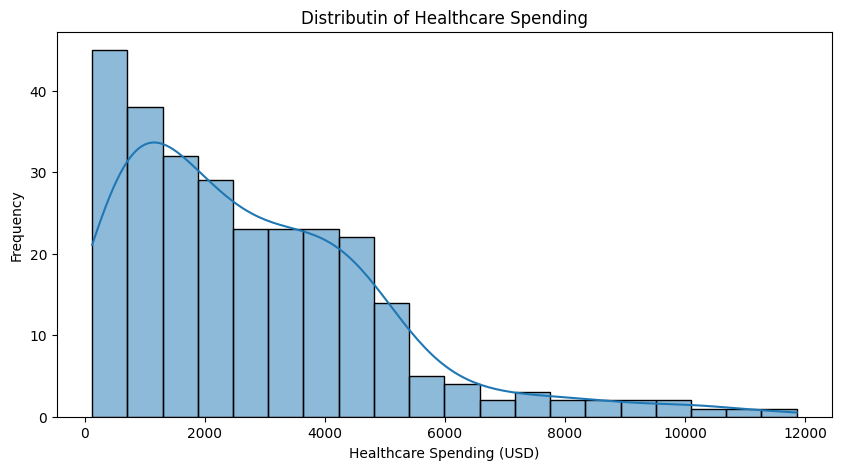

In [28]:
# histplot
plt.figure(figsize=(10,5))
sns.histplot(data=df,x="Spending_USD",
             bins=20,
             kde=True)
plt.title("Distribution of Healthcare Spending")
plt.xlabel("Healthcare Spending (USD)")
plt.ylabel("Frequency")
plt.show()

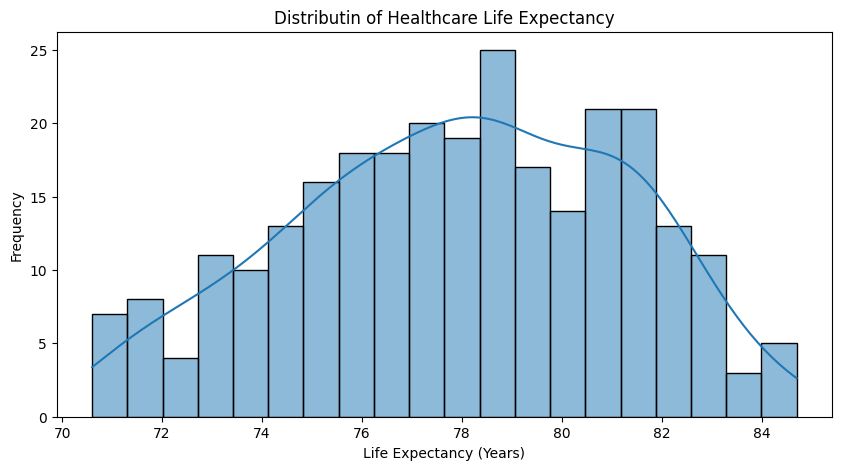

In [29]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,x="Life_Expectancy",
             bins=20,
             kde=True)
plt.title("Distributin of Healthcare Life Expectancy")
plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Frequency")
plt.show()

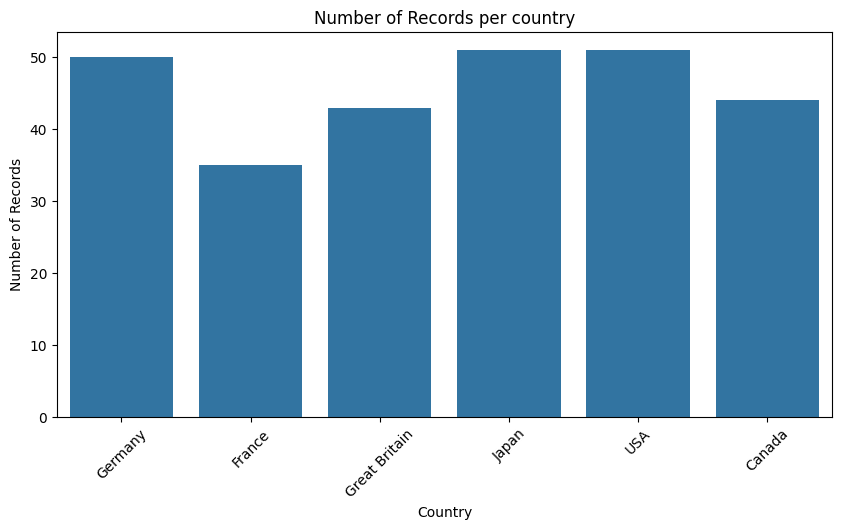

In [30]:
plt.figure(figsize=(10,5))
sns.countplot(data=df,x="Country")
plt.title("Number of Records per country")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()

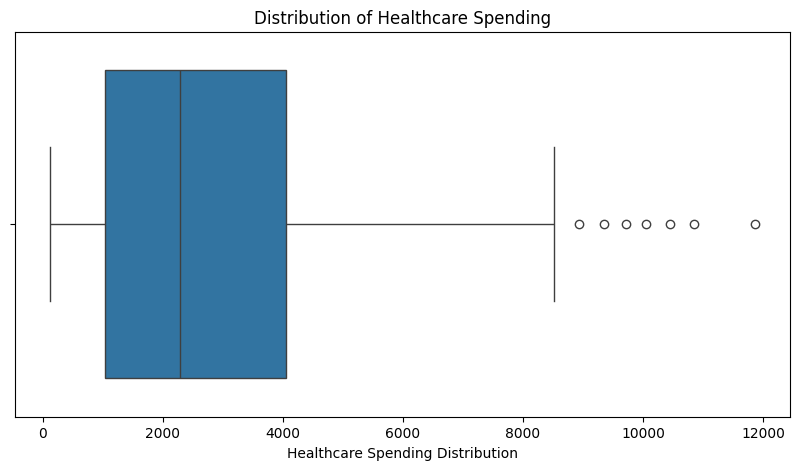

In [31]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x="Spending_USD")
plt.title("Distribution of Healthcare Spending")
plt.xlabel("Healthcare Spending Distribution")
plt.show()

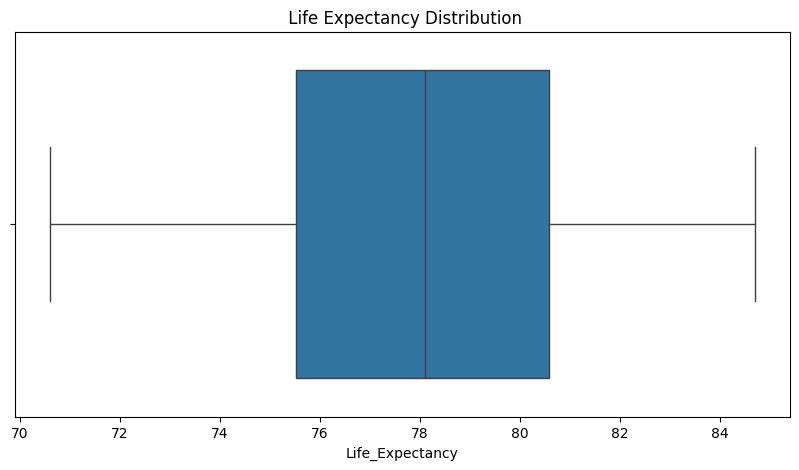

In [32]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x="Life_Expectancy")
plt.title(" Life Expectancy Distribution")

plt.show()

In [33]:
# Spending vs Life Expectancy

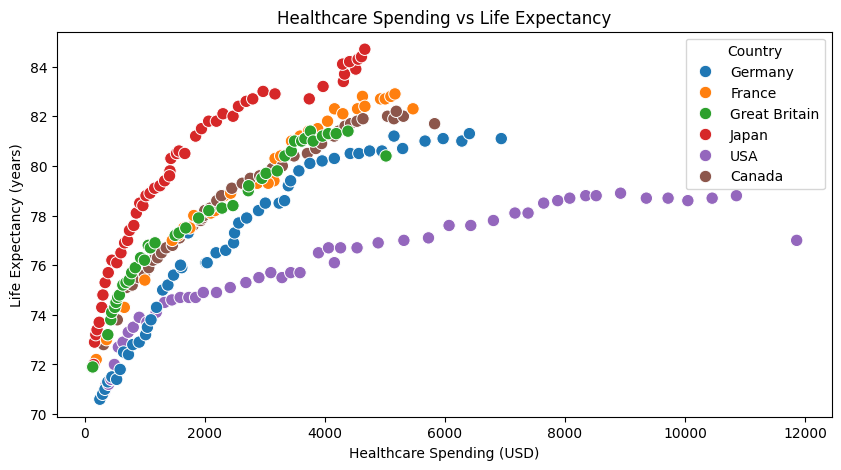

In [34]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df,x="Spending_USD",y="Life_Expectancy",hue="Country",s=80,)
plt.title("Healthcare Spending vs Life Expectancy")
plt.xlabel("Healthcare Spending (USD)")
plt.ylabel("Life Expectancy (years)")
plt.show()

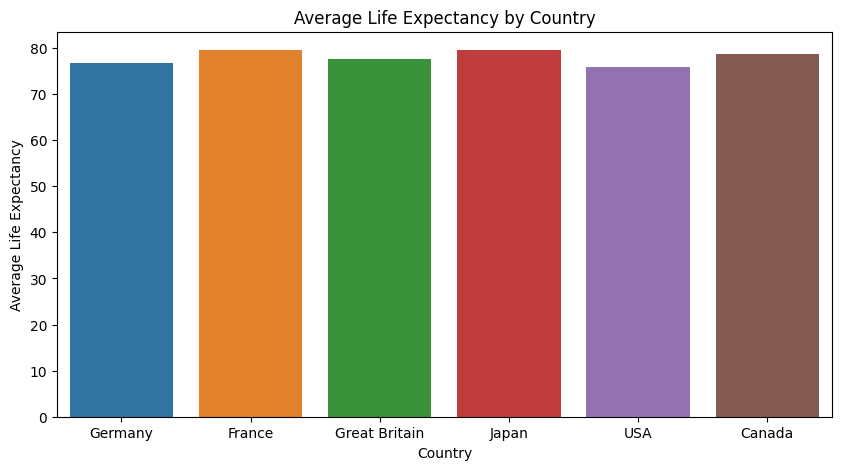

In [35]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="Country",y="Life_Expectancy",hue="Country",errorbar=None)
plt.title("Average Life Expectancy by Country")
plt.xlabel("Country")
plt.ylabel("Average Life Expectancy")
plt.show()

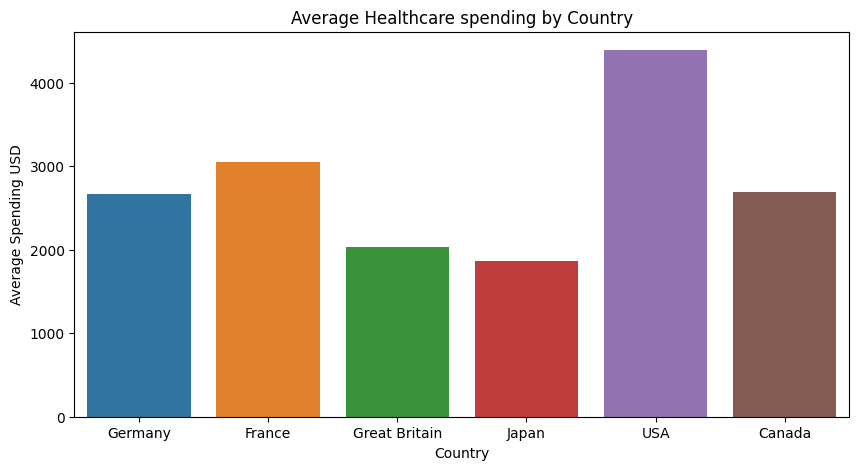

In [36]:
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="Country",y="Spending_USD",hue="Country",errorbar=None)
plt.title("Average Healthcare spending by Country")
plt.xlabel("Country")
plt.ylabel("Average Spending USD")
plt.show()

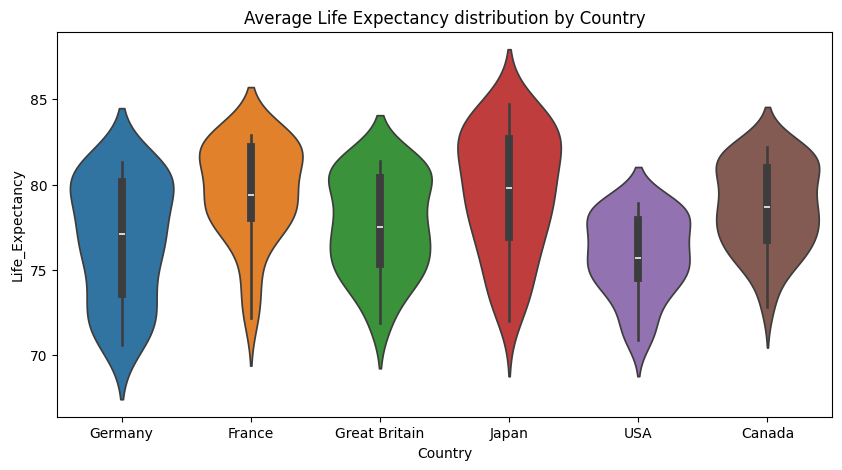

In [37]:
plt.figure(figsize=(10,5))
sns.violinplot(data=df,x="Country",y="Life_Expectancy",hue="Country")
plt.title("Average Life Expectancy distribution by Country")
plt.show()

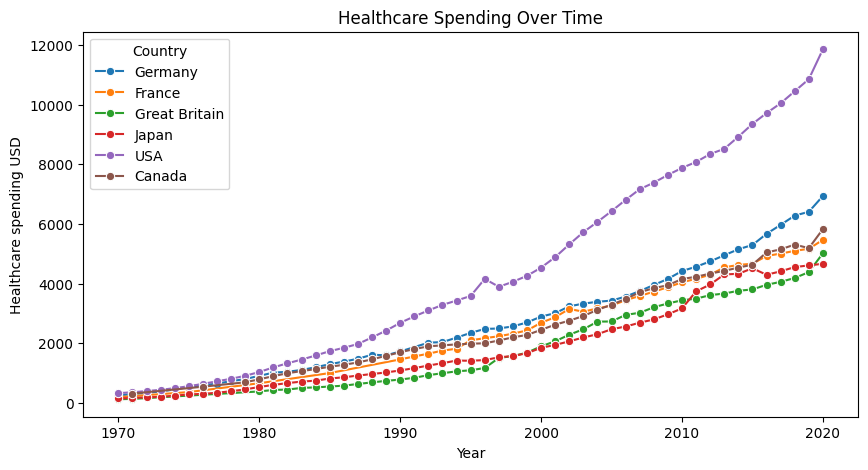

In [38]:
plt.figure(figsize=(10,5))
sns.lineplot(data=df,x="Year",y="Spending_USD",hue="Country",marker="o")
plt.title("Healthcare Spending Over Time")
plt.xlabel("Year")
plt.ylabel("Healthcare spending USD")
plt.show()

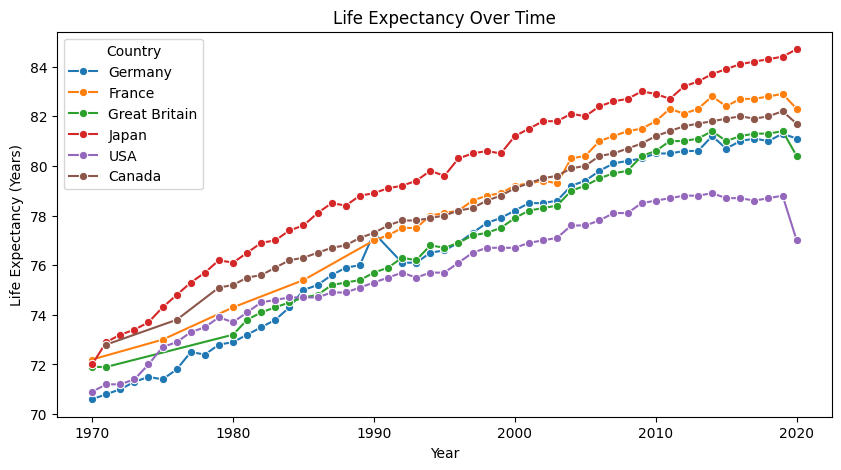

In [39]:
plt.figure(figsize=(10,5))
sns.lineplot(data=df,x="Year",y="Life_Expectancy",hue="Country",marker="o")
plt.title("Life Expectancy Over Time")
plt.xlabel("Year")
plt.ylabel("Life Expectancy (Years)")
plt.show()

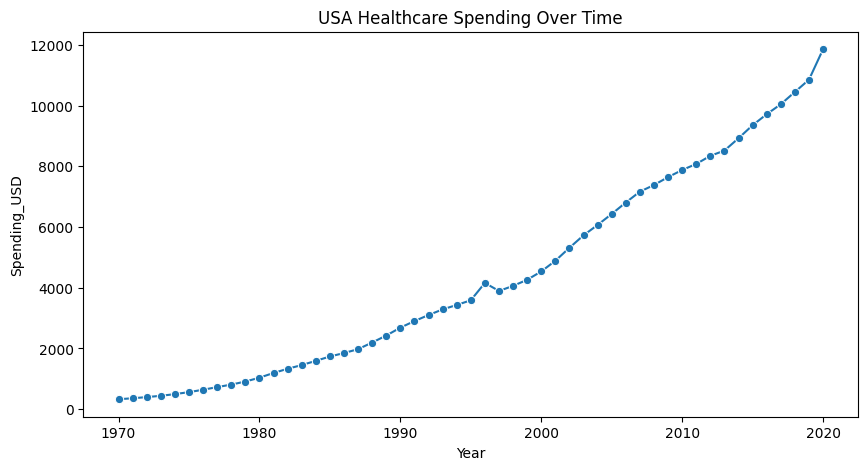

In [40]:
usa = df[df["Country"]=="USA"]

plt.figure(figsize=(10,5))
sns.lineplot(data=usa,x="Year",y="Spending_USD",marker="o")
plt.title("USA Healthcare Spending Over Time")
plt.show()

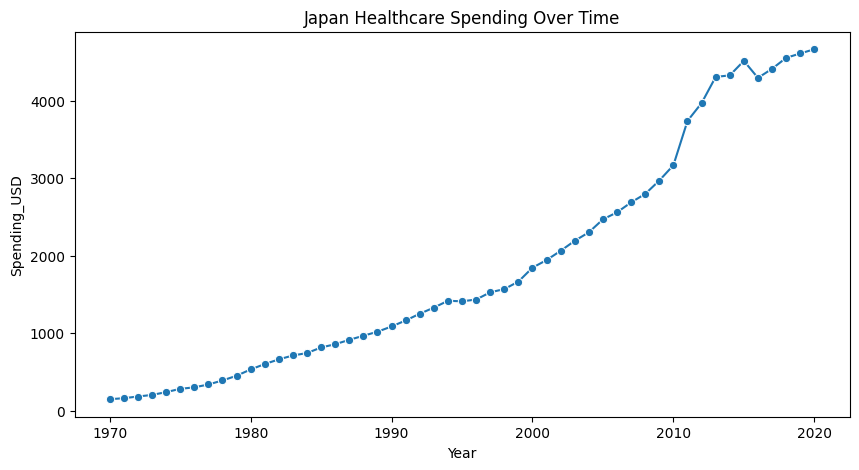

In [41]:
japan = df[df["Country"]=="Japan"]

plt.figure(figsize=(10,5))
sns.lineplot(data=japan,x="Year",y="Spending_USD",marker="o")
plt.title("Japan Healthcare Spending Over Time")
plt.show()

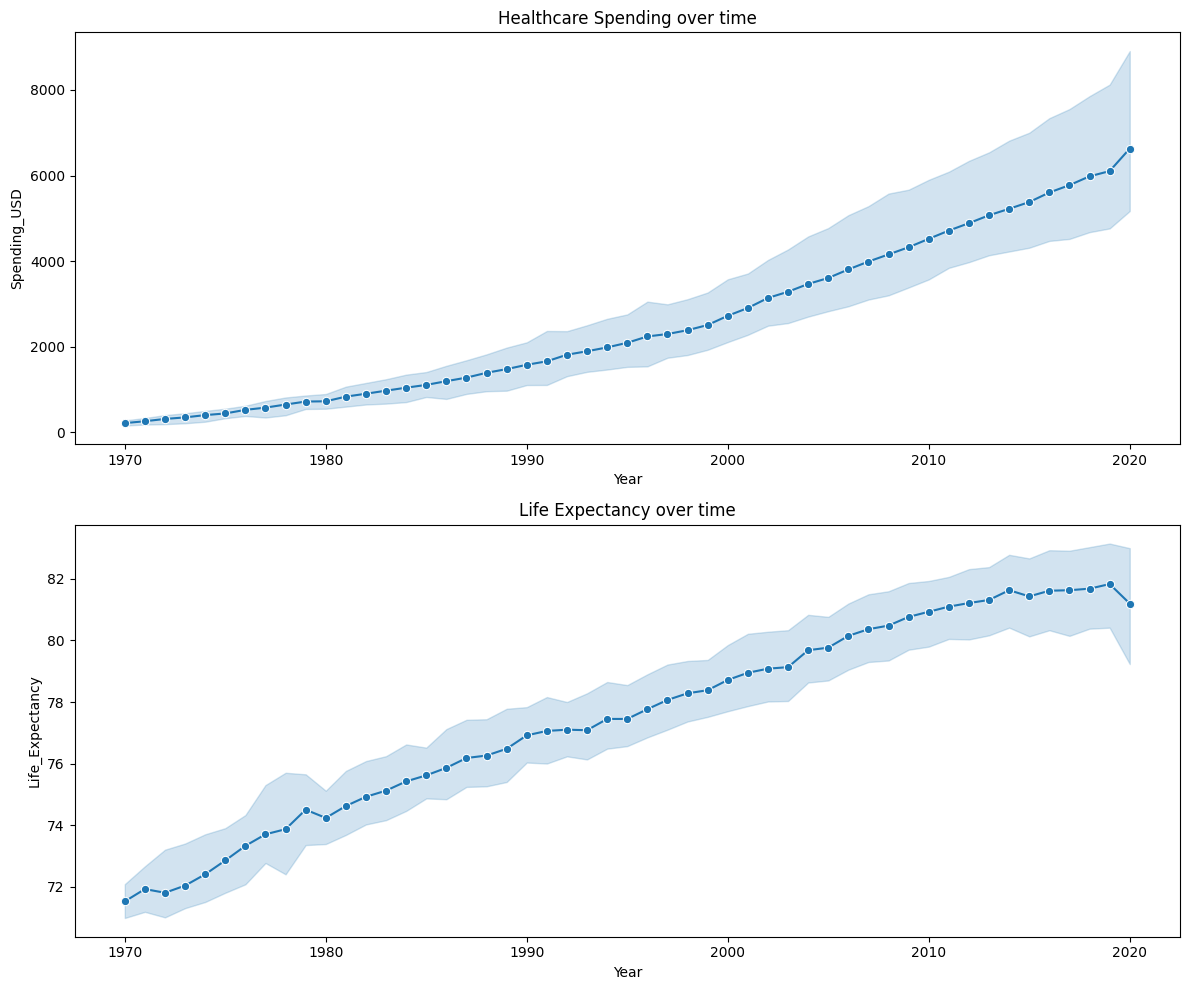

In [42]:
fig,axes = plt.subplots(2,1,figsize = (12,10))
sns.lineplot(data=df,x="Year",y="Spending_USD",marker="o",ax=axes[0])
axes[0].set_title("Healthcare Spending over time")

sns.lineplot(data=df,x="Year",y="Life_Expectancy",marker="o",ax=axes[1])
axes[1].set_title("Life Expectancy over time")

plt.tight_layout()
plt.show()

In [43]:
corr = df[["Year","Spending_USD","Life_Expectancy"]].corr()
corr

,Year,Spending_USD,Life_Expectancy
Year,1.000000,0.826273,0.902175
Spending_USD,0.826273,1.000000,0.579430
Life_Expectancy,0.902175,0.579430,1.000000


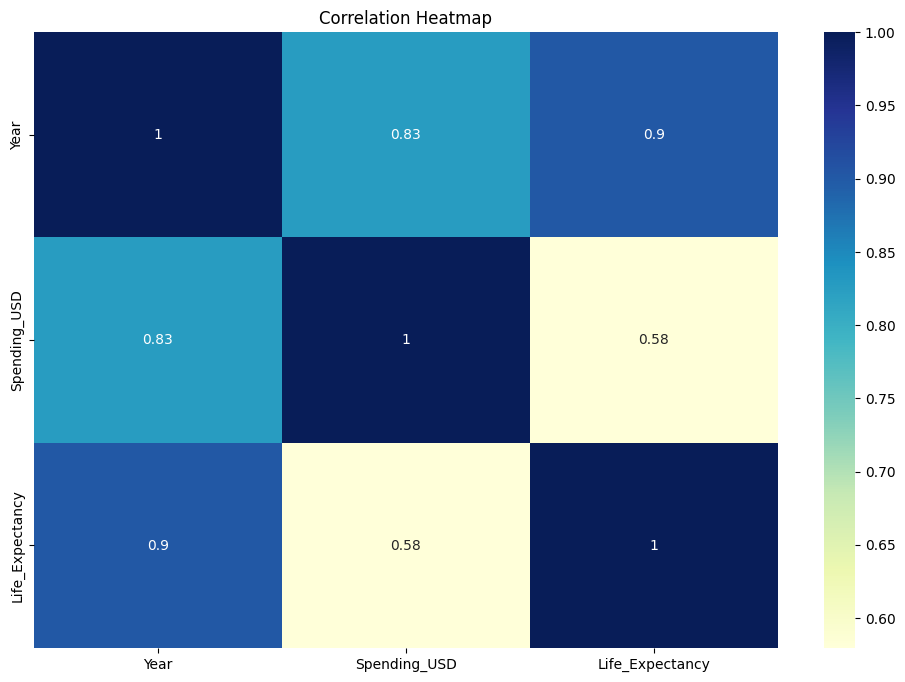

In [44]:
plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,cmap="YlGnBu")
plt.title("Correlation Heatmap")
plt.show()

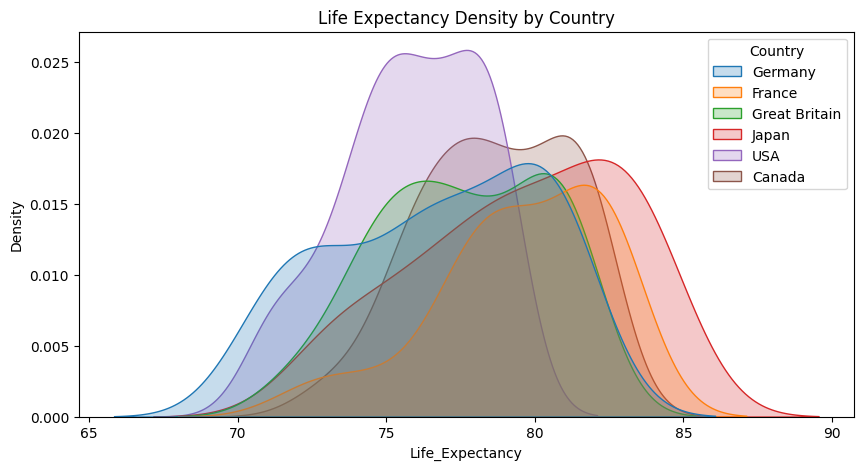

In [45]:
plt.figure(figsize=(10,5))
sns.kdeplot(data=df,x="Life_Expectancy",hue="Country",fill=True)
plt.title("Life Expectancy Density by Country")
plt.show()

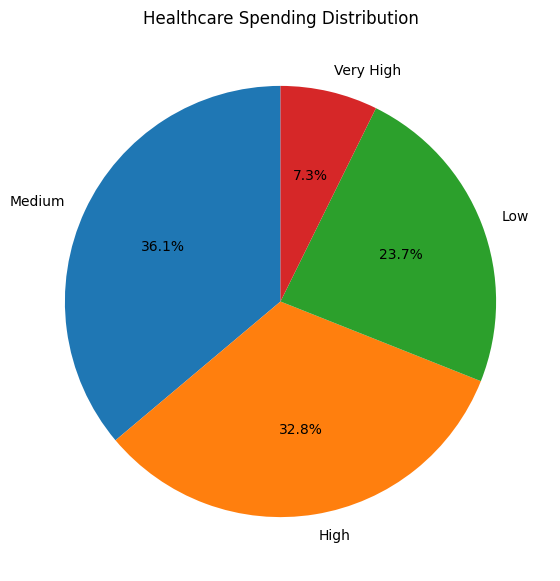

In [57]:
category_count = df["Spending_Category"].value_counts()
plt.figure(figsize=(7, 7))

plt.pie(
    category_count,
    labels=category_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Healthcare Spending Distribution")

plt.show()

# Conclusion
